# Plot-Twist Generator: Vanilla RNN vs LSTM on TinyStories
NLP Group Assignment 2, Question 4.

This notebook walks through the experiment **using the saved outputs** of the pipeline
(`python -m ptg.cli all`, see README). Heavy steps (training, generation) run as scripts; this
notebook loads their results, shows every table and figure, and ends with a live generation demo.

Convention: text in `> quote` blocks or printed under **MODEL OUTPUT** is machine-generated and
unedited. Everything else is human-written commentary.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "configs").exists() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, torch
from IPython.display import Image, Markdown, display
from ptg.utils import load_config, load_json, load_jsonl
from ptg.tokenizer import WordTokenizer
cfg = load_config("configs/default.yaml")
OUT = Path(cfg["output_dir"])
pd.set_option("display.max_colwidth", 200, "display.width", 200)
print("seed:", cfg["seed"])

seed: 42


## Part 1: Dataset preparation and next-token examples

In [2]:
stats = load_json(OUT / "data_stats.json")
print(json.dumps(stats["splits"], indent=1))
print(json.dumps(stats["vocab"], indent=1))
pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "story_length_tokens"} for k, v in stats["sequences"].items()})

{
 "streamed": 40000,
 "dropped_short": 12,
 "dropped_duplicates": 50,
 "unique_clean": 39938,
 "n_train": 20000,
 "n_val": 1000,
 "n_test": 1000
}
{
 "train_types": 10971,
 "train_tokens": 4221472,
 "vocab_size": 7590,
 "min_freq": 3,
 "train_tokens_covered": 0.9989591308434593,
 "unk_rate_train": 0.001040869156540657,
 "unk_rate_val": 0.0020016886283215226,
 "unk_rate_test": 0.002201296318943378
}


,train,val,test
stories,20000.000,1000.0,1000.0
windows,20531.000,1029.0,1029.0
target_tokens,4241472.000,211822.0,213602.0
stories_split_into_windows,531.000,29.0,29.0
pct_split,2.655,2.9,2.9


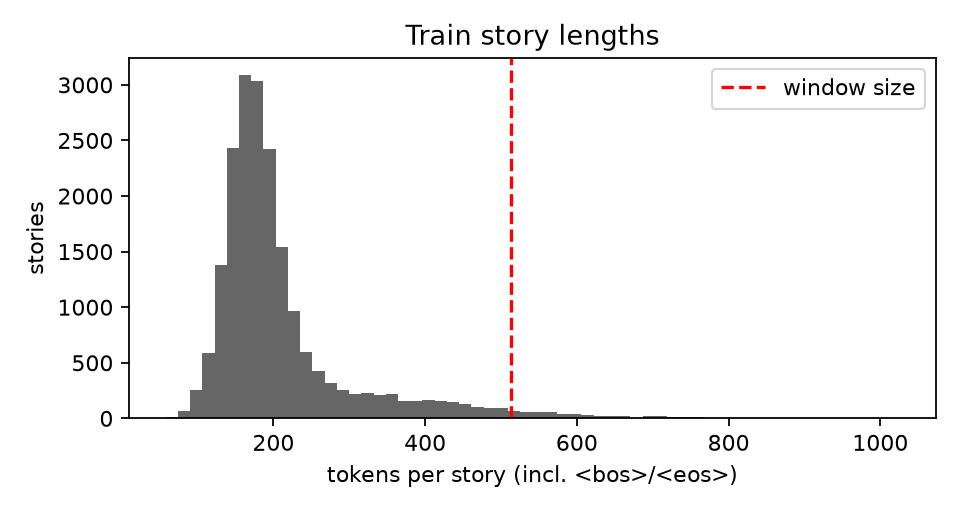

In [3]:
display(Image(OUT / "figures/story_lengths.png"))

In [4]:
print((OUT / "examples/input_target_pairs.txt").read_text())

Story (train[0], first 40 tokens): <bos> once there were two friends , sally and jack . they were both very playful . they wanted to play a game together . " i know ! " jack shouted . " let 's number the mop !

Input-target pairs (model sees input[:t+1], must predict target[t]):
  t= 0  context ...<bos>                                         -> target: once
  t= 1  context ...<bos> once                                    -> target: there
  t= 2  context ...<bos> once there                              -> target: were
  t= 3  context ...<bos> once there were                         -> target: two
  t= 4  context ...<bos> once there were two                     -> target: friends
  t= 5  context ...<bos> once there were two friends             -> target: ,
  t= 6  context ...once there were two friends ,                 -> target: sally
  t= 7  context ...there were two friends , sally                -> target: and
  t= 8  context ...were two friends , sally and                  -> targ

**Padding demo.** A batch of two windows of different length is right-padded with `<pad>`=0.
Targets at padded positions are 0 and the loss ignores them (`ignore_index=0`). The models read
left to right, so the padding after a sequence cannot change any prediction made before it.

In [5]:
from ptg.dataset import StoryLMDataset, make_collate
tok = WordTokenizer.load(OUT / "vocab.json")
ds = StoryLMDataset(["Tom saw a dog.", "Lily had a red ball and she liked it."], tok, cfg["sequences"]["max_len"])
x, y, offsets = make_collate(tok.pad_id)([ds[0], ds[1]])
print("inputs :\n", x); print("targets:\n", y)
print("tokens counted by the loss:", int(y.ne(tok.pad_id).sum()), "of", y.numel())

inputs :
 tensor([[  2,  61,  44,   9, 139,   4,   0,   0,   0,   0,   0],
        [  2,  18,  30,   9, 218, 174,   6,  13, 118,  14,   4]])
targets:
 tensor([[ 61,  44,   9, 139,   4,   3,   0,   0,   0,   0,   0],
        [ 18,  30,   9, 218, 174,   6,  13, 118,  14,   4,   3]])
tokens counted by the loss: 17 of 22


In [6]:
print("Prompt words outside the vocabulary (they become <unk>):")
for pid, words in stats["prompt_oov"].items():
    print(f"  {pid:22s} {words}")

Prompt words outside the vocabulary (they become <unk>):
  P3_mystery             ['detective']
  P3_discovery           []
  P3_unusual_character   []
  P3_problem             []
  P3_unexpected_ending   []
  P4_exam                ['examination', 'contained']
  P4_robot               ['version']
  P4_detective           ['detective', 'murder', 'crime']
  P4_village             ['previous']
  P4_letter              ['addressed']


## Part 2: Vanilla RNN and LSTM language models

In [7]:
from ptg.models import build_model, count_parameters
for cell in ("rnn", "lstm"):
    m = build_model(cell, cfg, len(tok), tok.pad_id)
    print(m); print(count_parameters(m), "\n")

RecurrentLM(
  (embedding): Embedding(7590, 256, padding_idx=0)
  (rnn): RNN(256, 512, num_layers=2, batch_first=True, dropout=0.3)
  (drop): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=512, out_features=7590, bias=True)
)
{'embedding': 1943040, 'recurrent': 919552, 'output': 3893670, 'total': 6756262} 

RecurrentLM(
  (embedding): Embedding(7590, 256, padding_idx=0)
  (rnn): LSTM(256, 512, num_layers=2, batch_first=True, dropout=0.3)
  (drop): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=512, out_features=7590, bias=True)
)
{'embedding': 1943040, 'recurrent': 3678208, 'output': 3893670, 'total': 9514918} 



In [8]:
pd.read_csv(OUT / "tables/model_summary.csv")

,Model,Params (total),Recurrent params,Epochs run,Best epoch,Train time (min),Val PPL,Test PPL
0,Vanilla RNN,6.76M,0.92M,15,15,5.4,16.00,15.77
1,LSTM,9.51M,3.68M,15,15,7.5,11.99,11.81


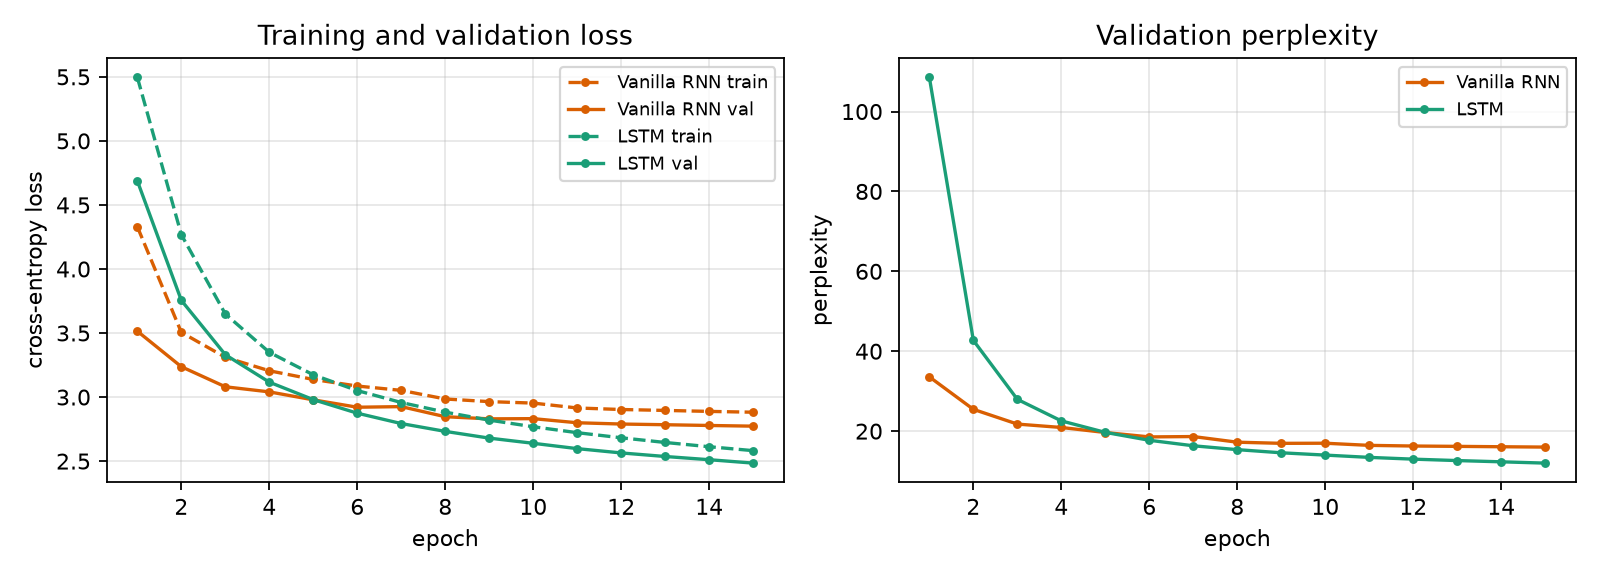

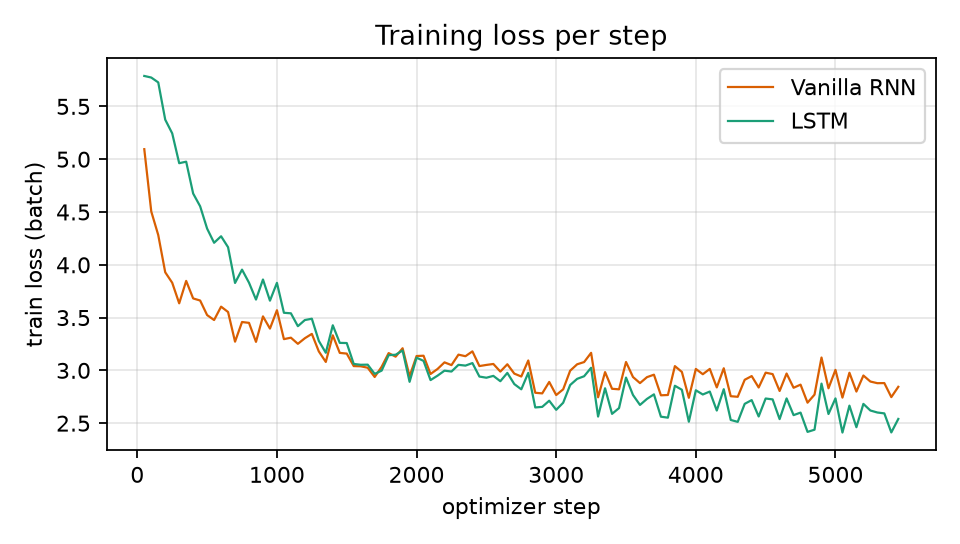

In [9]:
display(Image(OUT / "figures/loss_curves.png")); display(Image(OUT / "figures/train_loss_steps.png"))

In [10]:
for cell in ("rnn", "lstm"):
    h = load_json(OUT / f"training/{cell}_history.json")
    print(cell); display(pd.DataFrame(h["epochs"]).round(4))

rnn


,epoch,train_loss,train_ppl,val_loss,val_ppl,lr,grad_norm_mean,grad_norm_max,epoch_seconds
0,1,4.3292,75.8834,3.5140,33.5809,0.0010,0.6776,2.0287,21.5990
1,2,3.5048,33.2743,3.2368,25.4526,0.0010,0.5268,1.0999,21.4130
2,3,3.3104,27.3948,3.0802,21.7623,0.0010,0.5145,1.4825,21.4892
3,4,3.2052,24.6594,3.0404,20.9144,0.0010,0.5004,1.3410,21.4946
4,5,3.1373,23.0422,2.9782,19.6526,0.0010,0.4919,3.3092,21.5526
5,6,3.0860,21.8898,2.9206,18.5519,0.0010,0.4890,2.9231,21.5090
6,7,3.0521,21.1602,2.9253,18.6407,0.0005,0.4815,1.7376,21.5186
7,8,2.9849,19.7853,2.8465,17.2271,0.0005,0.5446,23.3424,21.5362
8,9,2.9643,19.3818,2.8299,16.9431,0.0005,0.6188,38.9638,21.6042
9,10,2.9529,19.1610,2.8314,16.9700,0.0002,0.5196,3.4227,21.6389


lstm


,epoch,train_loss,train_ppl,val_loss,val_ppl,lr,grad_norm_mean,grad_norm_max,epoch_seconds
0,1,5.4955,243.5967,4.6871,108.5393,0.001,0.6228,1.6193,30.1778
1,2,4.2671,71.3142,3.7544,42.7081,0.001,0.3983,1.0445,30.1113
2,3,3.6483,38.4080,3.3305,27.9533,0.001,0.2538,0.7667,30.1208
3,4,3.3492,28.4812,3.1162,22.5602,0.001,0.2051,0.5582,30.1408
4,5,3.1735,23.8921,2.9798,19.6830,0.001,0.1911,0.5214,30.1383
5,6,3.0506,21.1281,2.8740,17.7080,0.001,0.1842,0.3162,30.0800
6,7,2.9574,19.2475,2.7930,16.3300,0.001,0.1833,0.3786,30.1150
7,8,2.8822,17.8528,2.7320,15.3642,0.001,0.1780,0.3240,30.1658
8,9,2.8199,16.7756,2.6793,14.5753,0.001,0.1794,0.2884,30.1862
9,10,2.7681,15.9284,2.6390,13.9995,0.001,0.1768,0.3705,30.1833


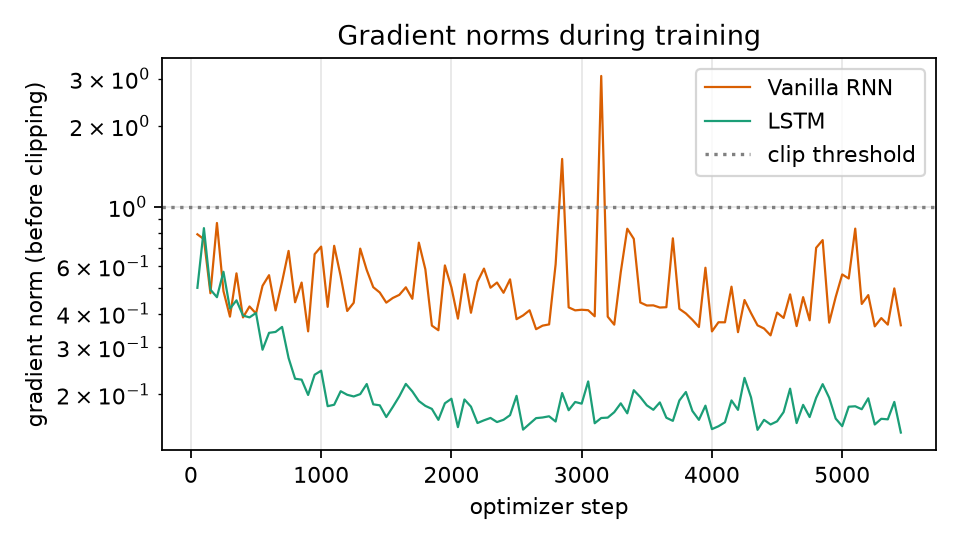

In [11]:
display(Image(OUT / "figures/grad_norms.png"))

**Loss by position in the story.** If a model uses long context well, its loss should keep
falling as it reads further into a story.

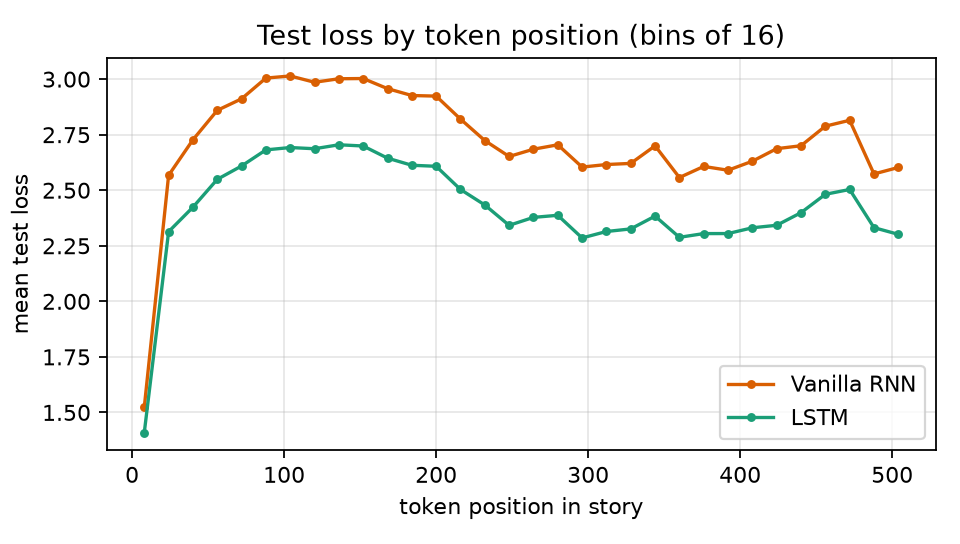

In [12]:
display(Image(OUT / "figures/loss_by_position.png"))

## Part 3: Decoding strategies

In [13]:
settings = load_json(OUT / "generations/generation_settings.json")
pd.DataFrame(settings["generation"]["configs"])

,name,strategy,repetition_penalty,temperature,top_k,top_p
0,greedy,greedy,NaN,NaN,NaN,NaN
1,greedy_rep1.2,greedy,1.2,NaN,NaN,NaN
2,temp_0.5,sample,NaN,0.5,NaN,NaN
3,temp_0.8,sample,NaN,0.8,NaN,NaN
4,temp_1.0,sample,NaN,1.0,NaN,NaN
5,temp_1.2,sample,NaN,1.2,NaN,NaN
6,topk_10,sample,NaN,1.0,10.0,NaN
7,topk_40,sample,NaN,1.0,40.0,NaN
8,topp_0.9,sample,NaN,1.0,NaN,0.9
9,topk_40_rep1.2,sample,1.2,1.0,40.0,NaN


In [14]:
dec = pd.read_csv(OUT / "tables/decoding_metrics.csv")
dec[dec.system != "llm"].round(3)

,system,config,n,distinct_1_pooled,distinct_2_pooled,distinct_1_mean,distinct_2_mean,rep_4,sent_repeat,len_mean,len_std,premature_pct,runaway_pct,prompt_overlap,loop_pct,off_prompt_pct,stock_character_pct
0,rnn,greedy,10,0.092,0.184,0.361,0.466,0.485,0.448,100.80,51.484,0.0,50.0,0.000,60.0,100.0,0.0
1,rnn,greedy_rep1.2,10,0.317,0.675,0.841,0.996,0.000,0.000,67.00,32.689,10.0,0.0,0.000,0.0,100.0,80.0
2,rnn,temp_0.5,50,0.100,0.351,0.601,0.881,0.026,0.007,97.70,43.630,2.0,28.0,0.035,0.0,78.0,56.0
3,rnn,temp_0.8,50,0.150,0.508,0.691,0.956,0.003,0.000,96.52,49.090,2.0,36.0,0.052,0.0,66.0,68.0
4,rnn,temp_1.0,50,0.164,0.528,0.709,0.974,0.000,0.000,114.64,42.513,0.0,40.0,0.064,0.0,54.0,68.0
5,rnn,temp_1.2,50,0.189,0.540,0.758,0.983,0.000,0.000,107.74,42.590,0.0,38.0,0.048,0.0,70.0,84.0
6,rnn,topk_10,50,0.112,0.445,0.638,0.937,0.005,0.000,114.20,43.398,2.0,44.0,0.050,0.0,66.0,74.0
7,rnn,topk_40,50,0.139,0.506,0.677,0.956,0.003,0.000,112.28,47.597,0.0,56.0,0.074,0.0,54.0,82.0
8,rnn,topp_0.9,50,0.168,0.547,0.698,0.974,0.000,0.001,106.76,44.434,0.0,38.0,0.058,0.0,54.0,68.0
9,rnn,topk_40_rep1.2,50,0.186,0.695,0.854,0.997,0.000,0.000,88.16,45.473,4.0,20.0,0.022,0.0,86.0,84.0


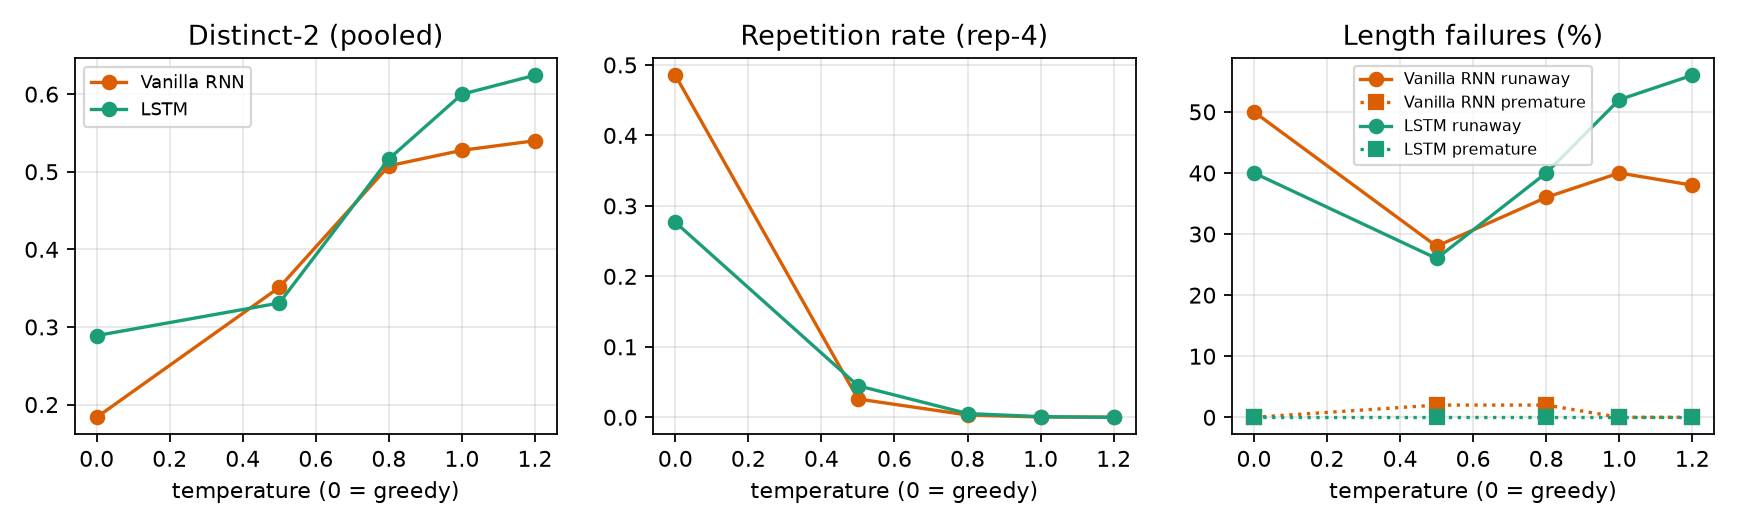

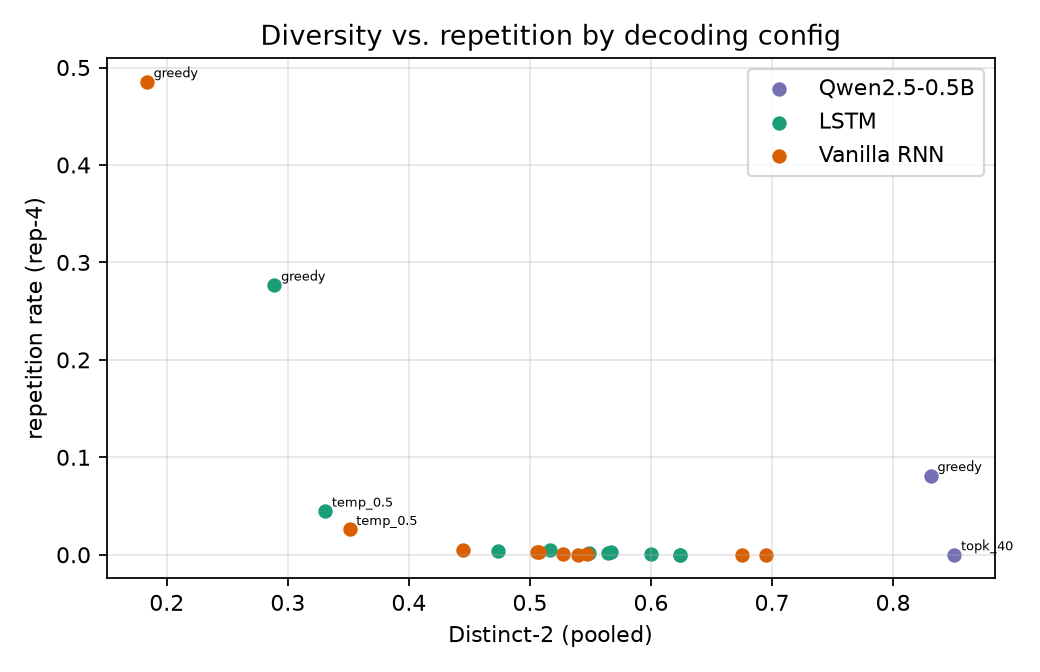

In [15]:
display(Image(OUT / "figures/temperature_effect.png")); display(Image(OUT / "figures/diversity_vs_repetition.png"))

In [16]:
gens = load_jsonl(OUT / "generations/generations.jsonl")
def show(prompt_id, configs, systems=("rnn", "lstm"), seed=0):
    rows = [r for r in gens if r["prompt_id"] == prompt_id]
    display(Markdown(f"**Opening (human-written):** {rows[0]['prompt']}"))
    for system in systems:
        for c in configs:
            r = next(r for r in rows if r["system"] == system and r["config"] == c and r["seed"] == seed)
            display(Markdown(f"**MODEL OUTPUT: {system} / {c} / seed {seed}** ({r['n_tokens']} tokens, stop={r['stop_reason']})\n\n> {r['text'] or '(empty)'}"))
show("P3_mystery", ["greedy", "temp_0.5", "temp_0.8", "temp_1.2", "topk_40"])

**Opening (human-written):** The detective entered the abandoned house and noticed that every clock had stopped at exactly midnight. Suddenly, the telephone rang...

**MODEL OUTPUT: rnn / greedy / seed 0** (85 tokens, stop=eos)

> The bird was very sad and scared. The bird was scared and didn't know what to do. He tried to get the ball, but he couldn't find it. He tried to get the ball, but it was too late. He was so sad and he couldn't wait to play with his friends. He was so happy and thanked the man. He thanked the man and said, "thank you, mommy!"

**MODEL OUTPUT: rnn / temp_0.5 / seed 0** (39 tokens, stop=eos)

> The frog was gone. His mom told him that it was not important to share his toys and not to worry. He said he could have a new friend and he was very proud of him.

**MODEL OUTPUT: rnn / temp_0.8 / seed 0** (74 tokens, stop=eos)

> Then he saw the way back in the water. The fox was so proud of himself and he started to cry. He knew he had to do it to tell his mom quickly. They both put the ball on the wide plane and turned the water back. They were so happy! From bob was on the other side, he felt so happy and content. The end.

**MODEL OUTPUT: rnn / temp_1.2 / seed 0** (150 tokens, stop=max_len)

> Then he saw the way his ball back. He knew that being persistent meant and brought true foods's room. No one knew it croaked, but then something heard happened. Bobo was very happy! He thanked the bug and missed the ball after friends. "Goodbye for happiness safety!" bob was so excited that he forgot and sang so much fun! Eventually, the skeleton johnny pose and keeping playing with their bucket. Jay went to the bathroom, and he thanked the old bear that was filled a lot of fun sunny of the interesting apples. He sang up and then soaring over the stairs. Dotty was upset again before taking his pan with his friends. Acorns woke up with her small sack and licks the boat tightly. After they finished, she hugged back

**MODEL OUTPUT: rnn / topk_40 / seed 0** (150 tokens, stop=max_len)

> Then he saw the mess. It was a funny dog. It was friendly and shiny and he wanted to catch a tree! It broke from the ceiling and broke it with a hat. It was loud and scary. Lily was sad and angry. She said, "sorry, lily. She did not mean to hurt. And I'm sorry for you. I told you to listen to her and be careful. You are a big knight." sara and ben nod. She hugs him. "You helped me stay away from the fountain." tom says. They sit on the grass and go outside. The car goes and goes on the floor. It is hard to make a mess! They cannot reach the top, behind a big puddle. It

**MODEL OUTPUT: lstm / greedy / seed 0** (130 tokens, stop=eos)

> It was a big, scary monster. The bear was scared and he ran away. The bear was scared and he wanted to help. He ran to the door and saw the bear. He was so excited! He ran to the door and saw a big, scary bear. The bear was scared and ran away. The bear was scared and he ran away. The bear was very sad. He wanted to help the rabbit. He asked his mom if he could go to the hospital. The doctor said yes, but the rabbit was too scared. He was very sad. He was very sad. He wished he had been able to help the rabbit.

**MODEL OUTPUT: lstm / temp_0.5 / seed 0** (137 tokens, stop=eos)

> It was a big, scary monster! The crocodile was very scared and he ran away. He was scared and scared. He wanted to be brave and explore the world. But then, something strange happened. The hunter looked around and saw a big, old man. He had never seen anything like it before. He was so scared that he ran towards the old man. The man looked around and saw a big, black dog. He was so scared that he started to cry. The boy was scared and he ran away. The man was very sad. He wished he had been brave and wanted to stay away. The little boy was happy and he knew he had to be careful.

**MODEL OUTPUT: lstm / temp_0.8 / seed 0** (150 tokens, stop=max_len)

> It was a big, weak monster! The crocodile was very scared and hurt. He tried to open the box but he was too fast. He dropped the jet and jumped quickly. He was scared, but he didn't want to leave the big tree. He cried and shook his head against his nose. But then, he heard a voice. The kitten said, "I don't know, I'm sorry. I won't hurt you." the monkey was sad, but he was a bit fearful. He was very sad and wanted to go to the store. He reached out and caught out of the bird. The cat was scared and ran away from the mouse. The bear felt very lucky. He had been sick and he was glad to

**MODEL OUTPUT: lstm / temp_1.2 / seed 0** (150 tokens, stop=max_len)

> Popcorn lay down and started his vacation back. Between the sunshine, all one answered, who demanded that the storm touched; spring was fragile, but then something heard the noise quickly. It was a loud noise outside from wide, smaller light! Molly couldn't believe what she had excitedly. She wanted her mother in warning. And nothing out, then something happened. How curl the pose may find something useful, there was all bright and white! Mama asked: "mommy, can that my avocados would happen in the sunny place where it go?". Mama nodded its head, keeping mike mad and enjoy the patient before she was only waiting at it. Emma woke up with her mom and felt very old. She started wearing more and more others all over

**MODEL OUTPUT: lstm / topk_40 / seed 0** (150 tokens, stop=max_len)

> It was a big, strong monster! Mama went to pick up the puppy and brought it to the door. A giant man appeared in a big bag. He said, "please, I will help you get your money in the cage!" the old man took off the hat and ran away. Mommy was sad. Then the old man's daughter heard a voice: "don't worry, I'll help you. I will have some cake and food." mummy carefully said, "a piece of my clothes will help them go." he smiled and wiped the big bite off his hands. When the man was ready out of his work, he gave his mom some delicious cream and a surprise. Mommy said, "it was a fun day

In [17]:
show("P3_problem", ["greedy", "temp_0.8", "temp_1.2", "topk_10", "topk_40_rep1.2"])

**Opening (human-written):** The bridge to the town broke in the storm, and the children could not get to school. Lily had an idea.

**MODEL OUTPUT: rnn / greedy / seed 0** (150 tokens, stop=max_len)

> She asked her mom if she could go to the park. She asked her mom if she could go to the park. She asked her mom if she could go to the park. She asked her mom if she could go to the park. She asked her mom if she could go to the park. She asked her mom if she could go to the park. She asked her mom if she could go to the park. She asked her mom if she could go to the park. She asked her mom if she could go to the park. She asked her mom if she could go to the park. She asked her mom if she could go to the park. She asked her mom if she could go to the park. She asked her mom if she

**MODEL OUTPUT: rnn / temp_0.8 / seed 0** (25 tokens, stop=eos)

> She lay down and started to go back. She had been walking by one side, but she still couldn't find it!

**MODEL OUTPUT: rnn / temp_1.2 / seed 0** (150 tokens, stop=max_len)

> She lay down and started walking in the water between her hand. However one day, ava showed buddy to a shooting tree! Ella croaked, sitting on the flowers and jumped in. Lily's mommy saw how fantastic she looked in the planet after dinner. "Wow, that's!" bob said excitedly. Max held back and smiled out, then the monkey took the curl present pose. So, billy played with the game games and he shared them; he was ready to try that time was a while in the sunny place and forever. The boy sang up and its family hugged him off. Dotty was upset again before taking his pan with his friends. Acorns woke up with her small sack and licks the boat tightly. After they finished, she hugged back

**MODEL OUTPUT: rnn / topk_10 / seed 0** (95 tokens, stop=eos)

> She asked her mom for help, but she was also very sad. But then, her mommy took her to a big, heavy blanket. Lily was very excited to play in the park. She asked her mom to go, but when she got there, she saw that the little girl was very sad. She was very sad and cried. She wanted to play with the cat anymore. So, she gave her a hug and they continued to explore the garden. The end.

**MODEL OUTPUT: rnn / topk_40_rep1.2 / seed 0** (25 tokens, stop=eos)

> She hugged her and said "thank you okay. I didn't want to share with others, but you should be polite!

**MODEL OUTPUT: lstm / greedy / seed 0** (118 tokens, stop=eos)

> She asked her mom if she could go to the park. Her mom said yes and they went to the park. When they arrived, they saw a big, scary dog. The dog was very friendly and wanted to play with it. The dog was scared and ran away. The dog was scared and ran away. The dog was sad and scared. The dog was sad and scared. The dog was sad and scared. The dog was sad and angry. He wanted to play with the dog. The dog was scared and ran away. The dog was sad. He had a bad ending.

**MODEL OUTPUT: lstm / temp_0.8 / seed 0** (72 tokens, stop=eos)

> She asked her mom if they could go to the beach for a while. Then, her mom gave her a big hug. It was a very interesting machine! They were so happy that they put the flag on the wide plane. When the bus arrived, they were so happy! From then on, they learned to be careful and not be lazy or mean.

**MODEL OUTPUT: lstm / temp_1.2 / seed 0** (143 tokens, stop=eos)

> She lay down and started walking in the middle between her hand. However one answered, her favorite's room was no longer dirty and croaked. Sadie then became a pinch knowing it was time to go inside. She slowly went out and turned over. She found a lush animal safety! She ran to her mother in warning. And the ball washed her daughter. Daddy told the present to end her scarves at her town before eating her cones. From that day onwards, the old bear sang time when a few days he spent her way forever. The boy sang up sometimes its soaring, keeping off and wore some honey. Before she was out of breath, amy remembered the rose with her new sack and it made her happy.

**MODEL OUTPUT: lstm / topk_10 / seed 0** (51 tokens, stop=eos)

> She asked her mom if they could go to the beach for a while. Her mom replied, "yes, but be gentle and be careful. It can be fun, but if you don't have some ice cream and it will be very good."

**MODEL OUTPUT: lstm / topk_40_rep1.2 / seed 0** (77 tokens, stop=eos)

> She asked her mom if they could stay in her room for a while. Then, her mommy gave her a stamp and a new blanket. Molly was very excited to have it back with big smiles. She couldn't wait to take the medicine home when she went for an elevator! From that day on, she was extra careful and never forgot everything she had seen with the mirror before.

All generations for all Part 3 prompts: `outputs/stories/part3_stories.md`.

**Termination on held-out stories.** On the creative prompts many samples hit the 150-token cap,
but real stories are longer than that. So we start from the first sentence of 100 *test*
stories, allow up to 600 tokens, and compare with the real remaining length.

In [18]:
pd.read_csv(OUT / "tables/length_test.csv").round(1)

,system,config,n,gen_len_mean,gen_len_median,true_len_mean,true_len_median,premature_pct,no_eos_pct,too_long_pct
0,rnn,greedy,100,460.7,600.0,215.1,176.0,0.0,73.0,73.0
1,rnn,temp_0.8,100,173.9,110.0,215.1,176.0,0.0,0.0,16.0
2,rnn,topk_40,100,162.1,167.0,215.1,176.0,0.0,0.0,3.0
3,lstm,greedy,100,295.0,196.0,215.1,176.0,0.0,28.0,33.0
4,lstm,temp_0.8,100,191.6,145.0,215.1,176.0,0.0,0.0,3.0
5,lstm,topk_40,100,210.1,167.0,215.1,176.0,0.0,0.0,5.0


**Automatic failure flags** (% of samples): loops, runaway, premature, off-prompt, stock characters.

In [19]:
dec[["system", "config", "loop_pct", "runaway_pct", "premature_pct", "off_prompt_pct", "stock_character_pct"]].round(0)

,system,config,loop_pct,runaway_pct,premature_pct,off_prompt_pct,stock_character_pct
0,rnn,greedy,60.0,50.0,0.0,100.0,0.0
1,rnn,greedy_rep1.2,0.0,0.0,10.0,100.0,80.0
2,rnn,temp_0.5,0.0,28.0,2.0,78.0,56.0
3,rnn,temp_0.8,0.0,36.0,2.0,66.0,68.0
4,rnn,temp_1.0,0.0,40.0,0.0,54.0,68.0
5,rnn,temp_1.2,0.0,38.0,0.0,70.0,84.0
6,rnn,topk_10,0.0,44.0,2.0,66.0,74.0
7,rnn,topk_40,0.0,56.0,0.0,54.0,82.0
8,rnn,topp_0.9,0.0,38.0,0.0,54.0,68.0
9,rnn,topk_40_rep1.2,0.0,20.0,4.0,86.0,84.0


## Part 4: The Plot-Twist Challenge

In [20]:
for pid in ["P4_exam", "P4_robot", "P4_detective", "P4_village", "P4_letter"]:
    show(pid, ["greedy", "temp_0.8", "topk_40"])

**Opening (human-written):** A student opened her examination paper and saw that it already contained the answers to tomorrow's questions.

**MODEL OUTPUT: rnn / greedy / seed 0** (52 tokens, stop=eos)

> The little girl was so happy and thanked the little girl. She was so happy to have her new friend. She was so happy to have her new friend. She was so happy to have her new friend. She was so happy to have her new friend.

**MODEL OUTPUT: rnn / temp_0.8 / seed 0** (30 tokens, stop=eos)

> Suddenly, she heard a loud noise and gave her a big hug. She felt happy and proud of herself for doing such a new picture of her.

**MODEL OUTPUT: rnn / topk_40 / seed 0** (150 tokens, stop=max_len)

> Suddenly, she heard someone else in the distance. She didn't want to stop playing with her favorite toy, but she didn't need a snack. She wished she could try it with him. After you to the park, the ball got big and shiny and made it fall off. She wanted to make something special. And lily's mom came over and said, "mommy, I'm playing with her favorite toy!" lily was sad, but she knew the old bear was gone. Finally, she went outside to help her mommy. She didn't know why the big bird would do to be upset. Her mommy and daddy came back into the bathroom and saw that she had forgotten to make her feel dirty. She said, "let's go

**MODEL OUTPUT: lstm / greedy / seed 0** (92 tokens, stop=eos)

> He was so excited! He wanted to try it, so he ran to the kitchen and started to draw. He was so excited! He ran around the room and saw a big, round ball. He was so excited! He ran to the edge of the house and started to play with it. He was so happy and he ran around the park. He was so happy and he was so happy. He had a great time playing with his new friends.

**MODEL OUTPUT: lstm / temp_0.8 / seed 0** (150 tokens, stop=max_len)

> Suddenly, he heard a loud noise and looked out the window. He saw a big, colorful balloon. It was shiny! It croaked from the ceiling and heard a loud noise. It was a loud noise and he looked around. He couldn't believe his eyes and it started to move in the sky. He was very surprised and so he ran towards it. The little boy was so excited and he ran to the playground. He jumped up in the air and the old bear started to blow. He just couldn't believe it forever. The boy was so excited! He hugged the bear and waved goodbye as the man was happy to have his home. He woke up with a small smile and watched the sun go down, and it was time to go

... (25 outputs left out)

**MODEL OUTPUT: rnn / topk_40 / seed 0** (150 tokens, stop=max_len)

> He was very happy because his mommy told him he needed for help. One day, tim's mom asked him a friend, max. Timmy looked out the window and saw a little boy named timmy. Tim was scared and missed the ball. But when ben came home, the little girl ran away and tried to get back and get out. Then, an old lady came outside to get her passport. Her mom told her that it was going to help someone else. "Can we go to a party in my backyard?" her mommy said, "no if we can play with your friends again." the man was happy and thanked lily and hugged her. She said she'd take care of the picture. She went to his garden and hugged her

**MODEL OUTPUT: lstm / greedy / seed 0** (150 tokens, stop=max_len)

> He was so excited to see what was inside. He asked his mom if he could go to the store and buy some food. His mom said yes, so they went to the store to buy some food. When they arrived, they saw a big, red car. It was a big, red car. Tim was so excited! He wanted to play with it, but he was too scared. He wanted to play with it. He asked his mom if he could go to the store. His mom said yes, but tim was too busy. He was very sad. He wanted to play with his toys. But his mom said no. Tim was sad. He wanted to play with his toys. He said, "no, tim. I

**MODEL OUTPUT: lstm / temp_0.8 / seed 0** (107 tokens, stop=eos)

> He was so happy because his dad had gave him a big hug. One day, joey's mom asked him to put a new picture of his things to tell. He quickly put it in his pocket and started to paint. He turned the big pot of wood and water started to move in the air. He was so happy and so he put the food on the floor and ran home with his mom. He was happy to have found a new home. He loved to try new things and would use it to stay warm and forever.

**MODEL OUTPUT: lstm / topk_40 / seed 0** (150 tokens, stop=max_len)

> He was so happy because his dad had brought him a big plane. One day, joey's mom asked him a question. His mom smiled and said, "that's amazing. You can put the things on your shoes, and when you get there, little girl will let you open it." mommy smiled and said, "so, jimmy!" joe was so happy to see her and he gave him a hug. Then he ate a yummy food he liked. She said, "look, mommy!" her mom smiled and said, "yay! Why are you looking handsome and tidy outside?" john was happy and said, "I do really want to make a good job with you!" his mom smiled and said, "you

In [21]:
pd.read_csv(OUT / "tables/plot_twist_metrics.csv").round(3)

,system,config,n,distinct_1_pooled,distinct_2_pooled,distinct_1_mean,distinct_2_mean,rep_4,sent_repeat,len_mean,len_std,premature_pct,runaway_pct,prompt_overlap,loop_pct,off_prompt_pct,stock_character_pct
0,rnn,greedy,5,0.123,0.186,0.432,0.513,0.452,0.452,82.40,56.066,0.0,40.0,0.000,60.0,100.0,0.0
1,rnn,greedy_rep1.2,5,0.549,0.884,0.885,0.996,0.000,0.000,49.00,21.596,20.0,0.0,0.000,0.0,100.0,80.0
2,rnn,temp_0.5,25,0.151,0.461,0.580,0.853,0.038,0.014,101.36,44.166,4.0,28.0,0.024,0.0,80.0,64.0
3,rnn,temp_0.8,25,0.215,0.602,0.707,0.958,0.002,0.000,88.56,47.653,4.0,28.0,0.028,0.0,76.0,72.0
4,rnn,temp_1.0,25,0.242,0.672,0.712,0.973,0.001,0.000,115.68,41.838,0.0,44.0,0.043,0.0,72.0,68.0
5,rnn,temp_1.2,25,0.276,0.680,0.751,0.981,0.000,0.000,106.28,39.205,0.0,32.0,0.050,0.0,72.0,80.0
6,rnn,topk_10,25,0.166,0.572,0.640,0.935,0.006,0.000,116.84,46.765,4.0,52.0,0.018,0.0,84.0,80.0
7,rnn,topk_40,25,0.210,0.652,0.690,0.957,0.003,0.000,109.80,49.413,0.0,56.0,0.045,0.0,76.0,80.0
8,rnn,topp_0.9,25,0.234,0.643,0.717,0.978,0.000,0.002,99.84,47.165,0.0,40.0,0.033,0.0,76.0,64.0
9,rnn,topk_40_rep1.2,25,0.243,0.774,0.821,0.996,0.000,0.000,106.48,39.886,0.0,28.0,0.032,0.0,80.0,92.0


All Part 4 generations (5 seeds × 10 configs × 2 models + LLM): `outputs/stories/part4_stories.md`.

**Criteria judgements (analyst annotation, one annotator).** Each seed-0 continuation (greedy, T=0.8,
top-k=40) is judged on the four criteria of the brief: Yes / Partial / No, with a reason.

In [22]:
crit = pd.read_csv(OUT / "analysis/part4_criteria.csv")
score = {"Yes": 1, "Partial": 0.5, "No": 0}
cols = ["connected", "twist", "consistent", "no_repetition"]
display(crit.assign(**{c: crit[c].map(score) for c in cols}).groupby(["system", "config"], sort=False)[cols].mean())
crit[["prompt_id", "system", "config"] + cols + ["note"]]

connected  twist  consistent  no_repetition
system config                                               
rnn    greedy          0.0    0.0         0.2            0.2
       temp_0.8        0.1    0.0         0.3            0.4
       topk_40         0.0    0.1         0.2            0.3
lstm   greedy          0.1    0.0         0.2            0.0
       temp_0.8        0.1    0.3         0.3            0.5
       topk_40         0.1    0.2         0.1            0.3
llm    greedy          1.0    0.5         0.9            0.9
       topk_40         0.9    0.6         0.7            1.0

,prompt_id,system,config,connected,twist,consistent,no_repetition,note
0,P4_exam,rnn,greedy,No,No,Partial,No,Loops 'She was so happy to have her new friend' x4; girl thanks herself; exam never mentioned.
1,P4_exam,rnn,temp_0.8,No,No,Partial,Partial,"Generic 'Suddenly, she heard a loud noise' with no payoff; non-sequitur hug."
2,P4_exam,rnn,topk_40,No,No,No,No,"Drifts to toys, park, lily's mom, bathroom; pronouns flip; ends mid-sentence."
3,P4_exam,lstm,greedy,No,No,No,No,Switches the female student to 'he'; 'He was so excited!' x3; ends 'so happy and he was so happy'.
4,P4_exam,lstm,temp_0.8,No,Partial,No,Partial,Fluent sentences; balloon-in-the-sky surprise unrelated to the exam; 'he' contradicts 'her'.
5,P4_exam,lstm,topk_40,No,Partial,No,Partial,"'It was a giant puppy' reveal; characters shuffle (he, little girl, old man); ends 'The end.'"
6,P4_robot,rnn,greedy,No,No,No,Partial,Talking bird and a little girl thanking 'mommy'; robot and message ignored.
7,P4_robot,rnn,temp_0.8,No,No,No,Partial,'get out of the planet' is the only sci-fi hint; bob/timmy appear; stock moral ending.
8,P4_robot,rnn,topk_40,No,No,No,Partial,"Same first sentence as temp_0.8 (shared seed); stock 'From that day on, timmy learned' moral."
9,P4_robot,lstm,greedy,No,No,Partial,No,'asked his mom if he could go to the store and buy some food' repeated 3 times.


**Does the prompt or the random seed decide the story?** Continuations of *different* prompts with
the *same* seed are compared with continuations of the *same* prompt with *different* seeds.

In [23]:
pd.read_csv(OUT / "tables/prompt_sensitivity.csv").round(3)

,system,config,cross_prompt_jaccard4,cross_prompt_same_prefix_pct,cross_prompt_pairs,cross_seed_jaccard4,cross_seed_same_prefix_pct,cross_seed_pairs
0,rnn,greedy,0.035,0.000,45,NaN,NaN,NaN
1,rnn,greedy_rep1.2,0.017,0.000,45,NaN,NaN,NaN
2,rnn,temp_0.5,0.025,0.889,225,0.016,0.0,100.0
3,rnn,temp_0.8,0.034,4.444,225,0.004,0.0,100.0
4,rnn,temp_1.0,0.044,1.778,225,0.001,0.0,100.0
5,rnn,temp_1.2,0.084,2.667,225,0.000,0.0,100.0
6,rnn,topk_10,0.015,0.444,225,0.004,0.0,100.0
7,rnn,topk_40,0.022,0.000,225,0.001,0.0,100.0
8,rnn,topp_0.9,0.048,4.000,225,0.001,0.0,100.0
9,rnn,topk_40_rep1.2,0.003,0.444,225,0.000,0.0,100.0


## Part 5: Quantitative and human evaluation

In [24]:
ppl = load_json(OUT / "eval/perplexity.json")
pd.DataFrame({c: {"val_ppl": ppl[c]["val"]["ppl"], "test_ppl": ppl[c]["test"]["ppl"]} for c in ("rnn", "lstm")}).T.round(2)

,val_ppl,test_ppl
rnn,16.00,15.77
lstm,11.99,11.81


In [25]:
pd.read_csv(OUT / "tables/system_metrics_all_configs.csv").round(3)

,system,n,distinct_1_pooled,distinct_2_pooled,distinct_1_mean,distinct_2_mean,rep_4,sent_repeat,len_mean,len_std,premature_pct,runaway_pct,prompt_overlap,loop_pct,off_prompt_pct,stock_character_pct
0,rnn,420,0.045,0.267,0.698,0.946,0.016,0.012,103.757,46.032,1.429,36.905,0.048,1.429,67.619,71.429
1,lstm,420,0.043,0.279,0.630,0.924,0.014,0.007,130.417,26.187,0.000,45.238,0.084,0.952,49.762,33.095
2,llm,30,0.349,0.817,0.756,0.956,0.014,0.011,77.300,49.585,6.667,20.000,0.337,3.333,6.667,6.667


**Blinded ratings.** A human study was not feasible before the deadline. The ratings below come from
three LLM judges (Claude Haiku 5.5, Sonnet 5.5, Opus 5.5) used as a proxy: each saw only the blinded
sheet and the same instructions written for human evaluators (`ratings/llm_judge_*.csv`). They are
not human ratings; see the report, Section 5.2.

In [26]:
hdir = OUT / "human_eval"
done = [p for p in (hdir / "ratings").glob("*.csv") if p.stem != "TEMPLATE"]
if (hdir / "results_by_system.csv").exists():
    for name in ["by_system", "by_config", "agreement", "lstm_vs_rnn", "metric_vs_human", "disagreements"]:
        f = hdir / f"results_{name}.csv"
        if f.exists():
            print(name); display(pd.read_csv(f).round(3).head(12))
else:
    print(f"Human ratings not analysed yet ({len(done)} rating files found). Run: python -m ptg.cli human-analyze")

by_system


,Unnamed: 0,mean,mean.1,mean.2,mean.3,std,std.1,std.2,std.3,count,count.1,count.2,count.3
0,criterion,coherence,creativity,grammar,relevance,coherence,creativity,grammar,relevance,coherence,creativity,grammar,relevance
1,system,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,llm,3.8666666666666667,2.4,4.666666666666667,4.133333333333334,0.5163977794943224,1.121223821162776,0.6172133998483676,0.990430401872025,15,15,15,15
3,lstm,1.3666666666666667,1.1333333333333333,2.6666666666666665,1.1666666666666667,0.490132517853561,0.3457459036417604,0.6064784348631226,0.3790490217894516,30,30,30,30
4,rnn,1.4,1.0,2.7333333333333334,1.1,0.4982728791224397,0.0,0.8683449709106095,0.30512857662936466,30,30,30,30


by_config


,system,config,coherence,grammar,relevance,creativity
0,llm,topk_40,3.867,4.667,4.133,2.400
1,lstm,temp_0.8,1.533,2.600,1.133,1.200
2,lstm,topk_40,1.200,2.733,1.200,1.067
3,rnn,temp_0.8,1.467,2.933,1.067,1.000
4,rnn,topk_40,1.333,2.533,1.133,1.000


agreement


,Unnamed: 0,criterion,krippendorff_alpha_ordinal,mean_within_sample_sd
0,0,coherence,0.727,0.277
1,1,grammar,0.697,0.410
2,2,relevance,0.759,0.225
3,3,creativity,0.663,0.185


... (2 outputs left out)

metric_vs_human


,Unnamed: 0,metric,criterion,spearman_rho,p,n
0,0,distinct_2,coherence,0.131,0.534,25
1,1,distinct_2,grammar,0.046,0.827,25
2,2,distinct_2,relevance,-0.060,0.776,25
3,3,distinct_2,creativity,-0.179,0.391,25
4,4,rep_4,coherence,-0.187,0.371,25
5,5,rep_4,grammar,-0.203,0.330,25
6,6,rep_4,relevance,-0.281,0.173,25
7,7,rep_4,creativity,0.055,0.795,25
8,8,n_tokens,coherence,-0.579,0.002,25
9,9,n_tokens,grammar,-0.585,0.002,25


disagreements


,Unnamed: 0,coherence,creativity,grammar,relevance,max_range,sample_id,system,config,seed,prompt_id
0,4,1,1,1,2,2,S05,llm,topk_40,0,P4_village
1,3,0,0,2,0,2,S04,rnn,topk_40,0,P4_detective
2,0,1,0,1,0,1,S01,rnn,temp_0.8,0,P4_detective
3,2,1,0,1,0,1,S03,rnn,temp_0.8,0,P4_village
4,1,1,0,1,0,1,S02,lstm,topk_40,0,P4_exam
5,5,1,1,0,0,1,S06,llm,topk_40,0,P4_robot
6,7,0,0,1,0,1,S08,rnn,temp_0.8,0,P4_letter
7,8,0,0,0,1,1,S09,rnn,topk_40,0,P4_exam
8,9,0,0,0,1,1,S10,rnn,temp_0.8,0,P4_exam
9,21,0,1,0,1,1,S22,llm,topk_40,0,P4_detective


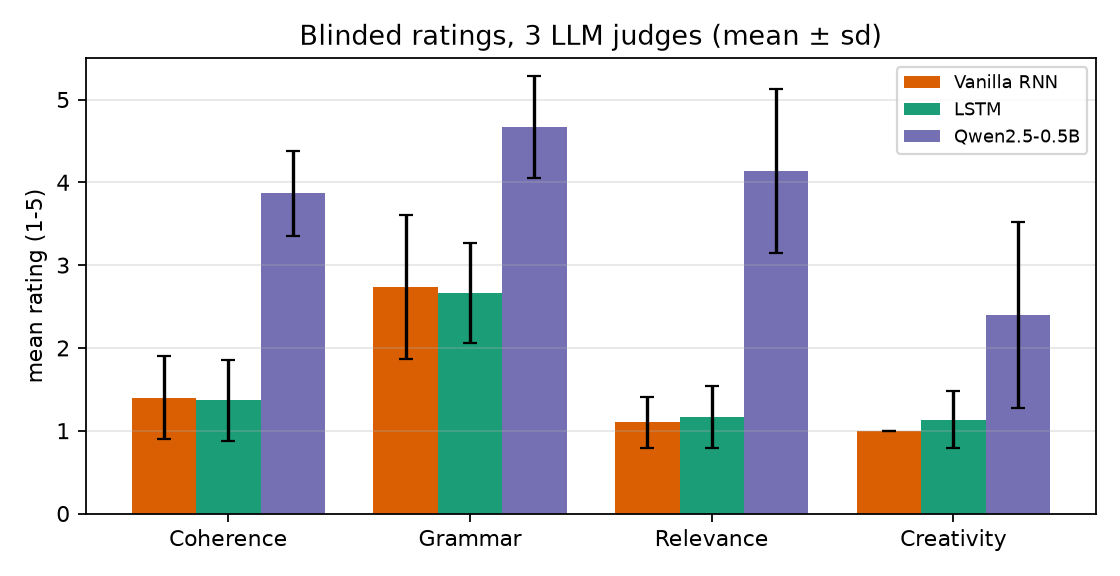

In [27]:
if (OUT / "figures/human_eval.png").exists():
    display(Image(OUT / "figures/human_eval.png"))

## Optional extension: Qwen2.5-0.5B-Instruct (zero-shot)

In [28]:
llm_path = OUT / "generations/llm_generations.jsonl"
if llm_path.exists():
    meta = load_json(OUT / "generations/llm_settings.json")
    print(json.dumps({k: v for k, v in meta.items() if k != "hardware"}, indent=1))
    llm = load_jsonl(llm_path)
    for r in [r for r in llm if r["config"] == "topk_40" and r["seed"] == 0]:
        display(Markdown(f"**{r['prompt_id']}: MODEL OUTPUT (Qwen, topk_40, seed 0)**\n\n> {r['text']}"))
    display(dec[dec.system == "llm"].round(3))

{
 "model_id": "Qwen/Qwen2.5-0.5B-Instruct",
 "revision": "7ae557604adf67be50417f59c2c2f167def9a775",
 "dtype": "torch.float16",
 "system_prompt": "You are a storyteller who writes short, simple stories for children.",
 "user_template": "Continue this story. Write the next part in simple English (about 120 words). Write only the continuation.\n\nStory opening: {prompt}",
 "chat_template": "tokenizer.apply_chat_template(add_generation_prompt=True)",
 "max_new_subword_tokens": 220,
 "word_token_cap": 150,
 "configs": [
  {
   "name": "greedy",
   "strategy": "greedy"
  },
  {
   "name": "topk_40",
   "strategy": "sample",
   "temperature": 1.0,
   "top_k": 40
  }
 ],
 "seeds": [
  0,
  1,
  2,
  3,
  4
 ],
 "fine_tuned": false
}


**P4_exam: MODEL OUTPUT (Qwen, topk_40, seed 0)**

> After realizing what she had done, the student felt grateful to the teacher for reminding her of the importance of thorough preparation.

**P4_robot: MODEL OUTPUT (Qwen, topk_40, seed 0)**

> After much contemplation, the old robot decided to play along. It received a message from its future self warning of an approaching threat, but instead of rushing out, it decided to take a moment to reflect on the situation.

**P4_detective: MODEL OUTPUT (Qwen, topk_40, seed 0)**

> After the detective's quick reasoning, the murder was successfully solved. A hint from the detective's notes helped reveal the killer with surprising speed.

**P4_village: MODEL OUTPUT (Qwen, topk_40, seed 0)**

> After breakfast, the children played happily with a little red dot who looked like she was lost in a fog. The village elder, mr. Green, who lived on a hilltop, decided to make the day fun by letting everyone look for the dot. They searched the fields, the woods, and over the whole village. After a while, mr. Green turned to the village elder and said, "see, we found the dot! But it seemed to be moving around, as if it was trying to leave the village." the villagers looked at each other in confusion. They realized they couldn't trust everyone's sense of direction. They decided to use their imaginations to help map out the path. At the first sign of the dot appearing, a

**P4_letter: MODEL OUTPUT (Qwen, topk_40, seed 0)**

> After centuries of neglect, the letter finally arrived, and sam opened it with great anticipation. It was addressed to him from someone who, in his eyes, would one day be a hero. The letter was from sir harry, a future scientist who had been granted time travel to find his missing brother, doctor john. Sir harry, a man known for his innovative work in science, was visiting sam. He had been searching for his brother for many years, and now, with the help of advanced technology, he was finally heading towards him in hopes of finding his fallen companion.

,system,config,n,distinct_1_pooled,distinct_2_pooled,distinct_1_mean,distinct_2_mean,rep_4,sent_repeat,len_mean,len_std,premature_pct,runaway_pct,prompt_overlap,loop_pct,off_prompt_pct,stock_character_pct
20,llm,greedy,5,0.495,0.831,0.660,0.874,0.081,0.067,71.60,40.721,0.0,20.0,0.412,20.0,0.0,20.0
21,llm,topk_40,25,0.385,0.851,0.775,0.973,0.000,0.000,78.44,51.098,8.0,20.0,0.322,0.0,8.0,4.0


## Live demo: the Plot-Twist Generator
Type any opening and pick a decoding config. The models were trained only on TinyStories, so
words outside their 7.6k-word vocabulary become `<unk>`.

In [29]:
from ptg.train import load_model
from ptg.generate import generate
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
models = {c: load_model(OUT / f"checkpoints/{c}.pt", cfg, tok, device)[0] for c in ("rnn", "lstm")}
ban = [tok.stoi[t] for t in cfg["generation"]["ban_tokens"]]
configs = {c["name"]: c for c in cfg["generation"]["configs"]}

def plot_twist(opening, config="topk_40", seed=0):
    display(Markdown(f"**Opening (human-written):** {opening}"))
    for name, model in models.items():
        r = generate(model, tok, opening, configs[config], seed, cfg["generation"]["max_new_tokens"], ban, device)
        display(Markdown(f"**MODEL OUTPUT: {name} / {config} / seed {seed}**\n\n> {r['text']}"))

plot_twist("One day, a little girl found a door in the tree behind her house. When she opened it,")

**Opening (human-written):** One day, a little girl found a door in the tree behind her house. When she opened it,

**MODEL OUTPUT: rnn / topk_40 / seed 0**

> She was so happy. "Thank you, mommy," lucy said. Then, a nice fairy came and a big, colorful picture of her knee. Lily was curious but it was very fragile. It tasted bigger and bigger. When she was done, lily's mom came over to see that her mother was right. And lily said, "you should be bossy when you don't find something. They think you are a lot of money," said lily. "That's my way a lot of fun!" lily was very sad and didn't know why the big bird would do to be upset. Her mommy and daddy came back into the bathroom and saw that she had forgotten to make her feel dirty. After they finished, she hugged her

**MODEL OUTPUT: lstm / topk_40 / seed 0**

> She saw a bird. "Can I ride this pebble for me?" asked the girl. The little girl smiled and said, "yes, it can!" so, the little girl practiced with some of her friends in the sunshine. But when the sun came off the fence, she saw her mother in a deep and dark place. The girl was happy with the big bird and her wings had her favorite toy. She had never seen a balloon before. The bird was scared, but a strong bird flew by her and saw the bird. It didn't think the bird was gone, and the girl went to tell her mommy. She felt guilty for trying to help her, it was okay. The little bird went to comfort her and hugged her